# P5 topic interactions

**Do topic-specific weights improve on P4 for unseen OP discussions within training?** Evaluate 3,451 published pairs using the original three OP-grouped folds. The [standalone script](train_p5_topic_interactions.py) uses the four signed P4 feature differences and the seven manually defined broad topics.

| Model | Predictors |
| --- | --- |
| P4 | Shared coefficients for word count, mean content-word Zipf, log reply delay, and external link presence |
| P5a · Primary | P4 plus topic-specific adjustments for all four features |
| P5b · Secondary | P4 plus topic-specific adjustments for reply delay only |

The comparison uses a symmetry-matched P4 refit. All three fits divide by the training-fold standard deviations and use zero intercept. Swapping A and B flips every feature difference and replaces the predicted probability with its complement. The archived P4 result is shown for context.

P5 models multiply each named topic indicator by the selected scaled A-minus-B differences. Multiplying interaction columns by 0.5 makes their effective L2 penalty four times that of the shared coefficients. The ratio is fixed in advance. Other / Unclear uses the shared coefficients. This is a penalized fixed-interaction model with shrinkage toward a common slope.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
RUNS = REPO / "project/data/processed/linguistic-features/paired-models/p5_topic_interactions"
RUN_ID = None  # Set a timestamp to reopen a particular run.
runs = sorted(RUNS.glob("*/results.json"))
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
run = report_path.parent
report = json.loads(report_path.read_text())
assert report["split"] == "train"
print(f"{report['pairs']:,} pairs across {report['discussions']:,} OP discussions.")
display(pd.DataFrame(report["folds"]).set_index("fold"))

3,451 pairs across 2,507 OP discussions.


,topic_training_labels,validation_discussions,validation_pairs
fold,,,
1,62,836,1149
2,68,836,1153
3,68,835,1149


## Predictive comparison

The primary result is **P5a minus symmetry-matched P4 in out-of-fold ROC-AUC**. P5b checks the prespecified timing-only variant. The paired intervals resample whole OP discussions with both models' out-of-fold predictions fixed. Lower log loss indicates better performance.

In [2]:
metrics = pd.read_csv(run / "predictive_metrics.csv")
display(metrics.pivot(index="metric", columns="model", values="value").reindex(
    columns=["Archived P4", "P4", "P5a", "P5b"],
).round(5))
changes = metrics.loc[metrics["model"].isin(["P5a", "P5b"])]
display(changes.set_index(["model", "metric"])[["delta_vs_p4", "delta_ci_low", "delta_ci_high"]].round(5))

model,Archived P4,P4,P5a,P5b
metric,,,,
Average precision,0.71836,0.71833,0.71234,0.71484
Log loss,0.60787,0.60794,0.61319,0.61113
Pairwise accuracy,0.66734,0.67053,0.66734,0.66879
ROC-AUC,0.73125,0.73140,0.72471,0.72788


delta_vs_p4  delta_ci_low  delta_ci_high
model metric                                                     
P5a   ROC-AUC               -0.00669      -0.01146       -0.00165
      Average precision     -0.00599      -0.01272        0.00070
      Pairwise accuracy     -0.00319      -0.01051        0.00487
      Log loss               0.00525       0.00099        0.00939
P5b   ROC-AUC               -0.00352      -0.00731        0.00031
      Average precision     -0.00349      -0.00758        0.00071
      Pairwise accuracy     -0.00174      -0.00839        0.00464
      Log loss               0.00319       0.00040        0.00579

## Out-of-fold topic assignment

Fit cosine centroids from named manual examples in the fitting OPs, requiring at least three examples per topic. Assign a named topic when its cosine similarity exceeds the runner-up by at least 0.025. The threshold and minimum support are fixed. Labeled OPs entering the outcome fit receive leave-one-out topic predictions. Validation topic predictions use only their existing OP embeddings and centroids from the fitting fold.

The embedding is a fixed pretrained title-and-body representation. The manual labels came from title review. They provide a small reference set for accuracy and coverage. The topic taxonomy was developed during exploration of the full training corpus, so this is an exploratory evaluation of that taxonomy.

In [3]:
topics = pd.read_parquet(run / "oof_topics.parquet")
reviewed = topics.loc[topics["manual_topic"].ne("")]
diag = report["topic_diagnostics"]
print(f"Named-topic coverage across all OPs: {diag['assigned_all']:,}/{len(topics):,}")
print(f"Correct named assignments among all reviewed titles with a named label: {diag['correct_manual_named']}/{diag['manual_named']}")
print(f"Accuracy among reviewed titles assigned a named topic: {diag['correct_when_assigned']}/{diag['assigned_reviewed']}")
print(f"Overall agreement including Other / Unclear: {diag['correct_manual_reviewed']}/{diag['manual_reviewed']}")
display(pd.crosstab(reviewed["manual_topic"], reviewed["oof_topic"], margins=True))
display(topics["oof_topic"].value_counts().to_frame("OP discussions"))

Named-topic coverage across all OPs: 1,994/2,507
Correct named assignments among all reviewed titles with a named label: 62/99
Accuracy among reviewed titles assigned a named topic: 62/82
Overall agreement including Other / Unclear: 63/100


oof_topic,"Arts, Media & Sports",Education & Work,Ethics & Religion,Other / Unclear,Politics & Law,Science & Health,Society & Identity,Technology & Economics,All
manual_topic,,,,,,,,,
"Arts, Media & Sports",7,1,0,3,1,0,0,0,12
Education & Work,1,12,0,0,0,0,0,0,13
Ethics & Religion,0,0,12,4,0,2,2,0,20
Other / Unclear,0,0,0,1,0,0,0,0,1
Politics & Law,0,0,0,2,14,0,0,1,17
Science & Health,0,0,4,2,1,3,1,0,11
Society & Identity,1,2,1,4,0,1,8,0,17
Technology & Economics,0,1,0,2,0,0,0,6,9
All,9,16,17,18,16,6,11,7,100


,OP discussions
oof_topic,
Other / Unclear,513
Politics & Law,494
Society & Identity,461
Ethics & Religion,432
Education & Work,198
"Arts, Media & Sports",159
Science & Health,135
Technology & Economics,115


## Coefficients and the timing contrast

For interpretation, refit on all training pairs using cross-fitted topic assignments and a common scaling reference. Coefficients are log-odds changes for one standard deviation of the A-minus-B feature difference. Timing is expressed as the log delay difference, so a negative timing coefficient favors the earlier reply.

Resample whole OP discussions and **refit** each penalized model 1,000 times. The intervals are conditional on the fixed topic assignments and scale. They do not include uncertainty in assigning topics. Each row reports how many unequal pairs and distinct discussions can inform that feature. The timing contrast directly subtracts the Politics & Law coefficient from the Technology & Economics coefficient in each bootstrap replicate.

In [4]:
coef = pd.read_csv(run / "topic_coefficients.csv")
contrast = pd.read_csv(run / "timing_contrasts.csv")
names = {
    "a_minus_b_word_count": "Word count",
    "a_minus_b_mean_content_word_zipf": "Mean content-word Zipf",
    "a_minus_b_log1p_reply_delay_minutes": "Log reply delay",
    "a_minus_b_has_external_link": "External link",
}
coef["feature"] = coef["feature"].map(names)
display(contrast.set_index("model").round(4))
display(coef.set_index(["model", "topic", "feature"])[[
    "informative_pairs", "informative_discussions", "coefficient", "ci_low", "ci_high",
]].round(4))

,contrast,estimate,ci_low,ci_high
model,,,,
P5a,Technology & Economics minus Politics & Law,-0.0416,-0.4109,0.3338
P5b,Technology & Economics minus Politics & Law,-0.0275,-0.3917,0.3406


informative_pairs  informative_discussions  coefficient  ci_low  ci_high
model topic                  feature                                                                                         
P5a   Shared                 Word count                           3442                     2501       0.7605  0.5776   0.9647
                             Mean content-word Zipf               3450                     2506      -0.3753 -0.5275  -0.2302
                             Log reply delay                      3451                     2507      -0.4041 -0.5625  -0.2645
                             External link                         733                      672       0.2280  0.0958   0.3737
      Arts, Media & Sports   Word count                            217                      157       0.7162  0.4021   1.1884
                             Mean content-word Zipf                218                      158      -0.6304 -0.9879  -0.3447
                             Log reply delay                       219                      159      -0.2545 -0.5272   0.0446
                             External link                          45                       40       0.1687 -0.1865   0.5315
      Education & Work       Word count                            288                      198       0.5447  0.2566   0.9365
                             Mean content-word Zipf                288                      198      -0.2298 -0.4773   0.0016
                             Log reply delay                       288                      198      -0.4056 -0.6794  -0.1777
                             External link                          46                       43       0.2838 -0.0008   0.5891
      Ethics & Religion      Word count                            599                      431       0.6924  0.4875   0.9743
                             Mean content-word Zipf                600                      432      -0.4195 -0.6124  -0.2467
                             Log reply delay                       600                      432      -0.3474 -0.5462  -0.1652
                             External link                         131                      120       0.3358  0.1565   0.5582
      Politics & Law         Word count                            641                      493       0.7281  0.5334   0.9966
                             Mean content-word Zipf                643                      494      -0.4807 -0.6800  -0.2848
                             Log reply delay                       643                      494      -0.2284 -0.4081  -0.0576
                             External link                         153                      137       0.2129  0.0464   0.4178
      Science & Health       Word count                            208                      135       0.7191  0.3733   1.2205
                             Mean content-word Zipf                208                      135      -0.3469 -0.6804  -0.0517
                             Log reply delay                       208                      135      -0.4002 -0.7616  -0.1197
                             External link                          51                       44       0.3874  0.0828   0.7379
      Society & Identity     Word count                            628                      460       0.9767  0.7177   1.2623
                             Mean content-word Zipf                630                      461      -0.4437 -0.6427  -0.2693
                             Log reply delay                       630                      461      -0.4156 -0.5980  -0.2471
                             External link                         115                      109       0.2782  0.1014   0.4871
      Technology & Economics Word count                            158                      115       0.9379  0.5886   1.3503
                             Mean content-word Zipf                158                      115      -0.3637 -0.7494  -0.0924
                     

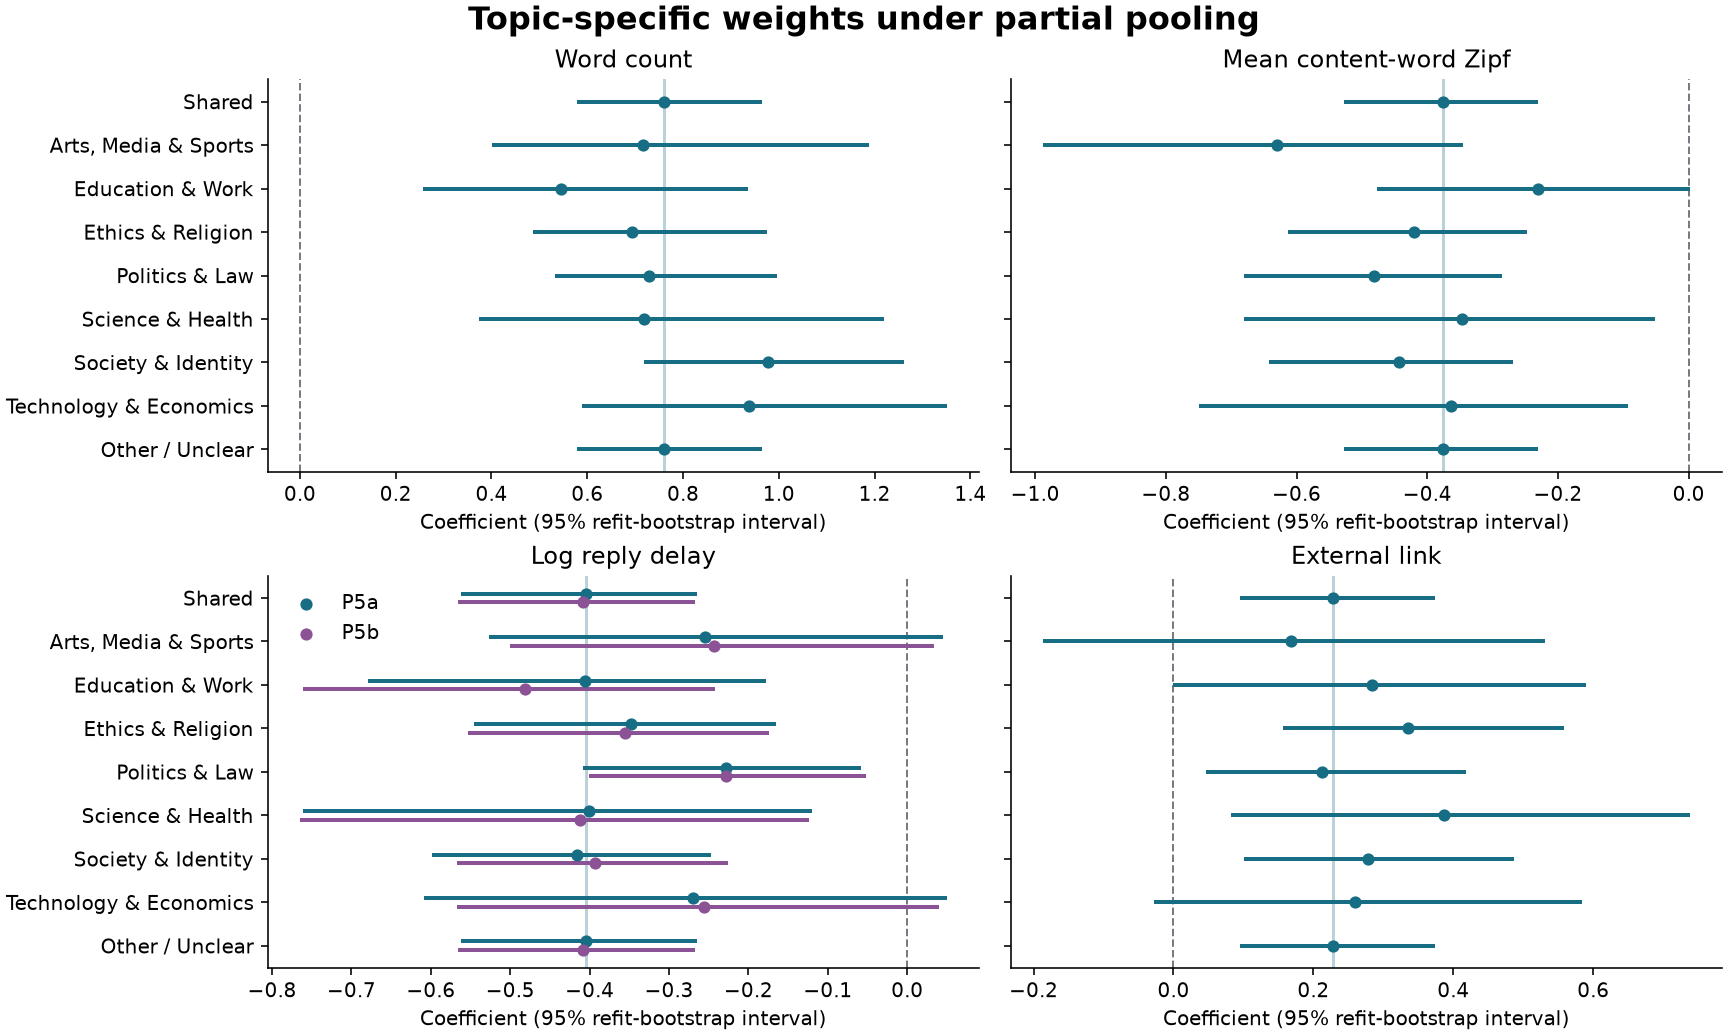

In [5]:
import matplotlib.pyplot as plt

primary = coef.loc[coef["model"].eq("P5a")]
topic_order = primary["topic"].drop_duplicates().tolist()
positions = np.arange(len(topic_order))
fig, axes = plt.subplots(2, 2, figsize=(12, 7.2), sharey=True, layout="constrained")
for ax, feature in zip(axes.flat, names.values()):
    group = primary.loc[primary["feature"].eq(feature)].set_index("topic").loc[topic_order]
    overlay = feature == "Log reply delay"
    y = positions - 0.10 if overlay else positions
    ax.axvline(0, color="#757c84", linestyle="--", linewidth=1)
    ax.axvline(group.loc["Shared", "coefficient"], color="#176d83", alpha=0.30)
    ax.hlines(y, group["ci_low"], group["ci_high"], color="#176d83", lw=2)
    ax.scatter(group["coefficient"], y, color="#176d83", s=26, label="P5a", zorder=3)
    if overlay:
        secondary = coef.loc[coef["model"].eq("P5b") & coef["feature"].eq(feature)].set_index("topic").loc[topic_order]
        ax.hlines(positions + 0.10, secondary["ci_low"], secondary["ci_high"], color="#8b5395", lw=2)
        ax.scatter(secondary["coefficient"], positions + 0.10, color="#8b5395", s=26, label="P5b", zorder=3)
        ax.legend(frameon=False)
    ax.set(title=feature, xlabel="Coefficient (95% refit-bootstrap interval)")
    ax.set_yticks(positions, topic_order)
    ax.spines[["top", "right"]].set_visible(False)
axes.flat[0].invert_yaxis()
fig.suptitle("Topic-specific weights under partial pooling", weight="bold", fontsize=16)
plt.show()